# Simulations: Should sample size be contractible?

Gaussian model $X_i \overset{iid}{\sim} \mathcal{N}(\theta, 1)$, evidence $Z_n = \sqrt{n}\,\bar X_n \sim \mathcal{N}(\theta\sqrt n, 1)$, linear cost $c(n) = c_0 + c_1 n$, max license value $R$.

By the Neyman–Pearson / Karlin–Rubin characterization, the optimal incentive-aligned contract of each type is an **all-or-nothing threshold rule on $Z_n$**, so the two contracts differ *only in their testing level*:

- **Contract A** (sample size not contractible): null deterrence must hold at the null's cheapest deviation, so the level is
  $\alpha_A = \min\{1,\; c_{\min}/R\}$ with $c_{\min} = \min_{n \in \mathcal N} c(n)$, *uniform in $n$*.
- **Contract B** (sample size contractible): the option at $n$ needs only $R\,\alpha \le c(n)$, so
  $\alpha_B(n) = \min\{1,\; c(n)/R\}$.

Passing probability of type $\theta$ at sample size $n$ and level $\alpha$:
$$ p(n, \theta; \alpha) = 1 - \Phi\big(z_{1-\alpha} - \theta\sqrt{n}\big), $$
which is exact (no Monte Carlo needed). The agent solves
$$ n^*_j(\theta) \in \arg\max_{n \in \mathcal N} \; v_j(\theta, n) = R\,p_j(n,\theta) - c(n), \qquad V_j(\theta) = \max\{0, \max_n v_j(\theta,n)\}. $$

**What we want the figures to show**
1. Headline: $p_B(n^*_B(\theta), \theta) \ge p_A(n^*_A(\theta), \theta)$, with a *strict* gap for moderate $\theta$.
2. Participation: $V_B \ge V_A$, hence a lower participation threshold $\bar\theta_B \le \bar\theta_A$.
3. Chosen sample sizes $n^*_A$ vs $n^*_B$.
4. Comparative statics: the benefit of contractibility grows with the cost slope $c_1$ (the "costly experiments" story) and shrinks with $R$.
5. Shape of the objective: where the agent's profit $v_j(\theta, n)$ is convex or concave in $n$ (Proposition 2, Lemma 2), and how a strict test ($z_A > 2$) creates a convex region under Contract A.


In [15]:
import numpy as np
from scipy.stats import norm
from scipy.optimize import brentq
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.grid": True,
    "grid.alpha": 0.3, "lines.linewidth": 2,
})

COL_A, COL_B = "#c0392b", "#2471a3"  # A = red, B = blue


## Model primitives

In [16]:
def alpha_A(R, c0, c1, N):
    '''Contract A testing level: pinned by the cheapest feasible experiment.'''
    c_min = c0 + c1 * N.min()
    return min(1.0, c_min / R)

def alpha_B(n, R, c0, c1):
    '''Contract B testing level at contracted sample size n.'''
    return np.minimum(1.0, (c0 + c1 * n) / R)

def passing_prob(n, theta, alpha):
    '''P_theta(Z_n > z_{1-alpha}); exact Gaussian power. alpha=1 -> pass w.p. 1.'''
    n, alpha = np.asarray(n, float), np.asarray(alpha, float)
    out = np.where(
        alpha >= 1.0, 1.0,
        1.0 - norm.cdf(norm.ppf(1.0 - np.clip(alpha, 1e-12, 1 - 1e-12)) - theta * np.sqrt(n))
    )
    return out

def best_response(theta, R, c0, c1, N, tol=1e-7):
    '''Agent's optimal n, passing prob, and utility under both contracts.

    Returns dict with n*, p(n*), v(n*) for j in {A, B} (v clipped at 0 with
    participation flag). Ties in argmax broken toward smaller n.
    `tol` guards the participation test against floating-point noise: the
    null type is exactly indifferent (v = 0 at every n), so without it the
    argmax at theta = 0 is decided by ~1e-14 roundoff and a spurious n* is
    reported for a type that in fact opts out.'''
    cost = c0 + c1 * N
    aA = alpha_A(R, c0, c1, N)
    aB = alpha_B(N, R, c0, c1)

    res = {}
    for j, alph in (("A", np.full_like(N, aA, dtype=float)), ("B", aB)):
        p = passing_prob(N, theta, alph)
        v = R * p - cost
        i = int(np.argmax(v))            # first (smallest-n) maximizer
        participates = v[i] > tol            # v = 0 (up to roundoff) -> opt out
        res[j] = dict(n=int(N[i]) if participates else None,
                      p=float(p[i]) if participates else 0.0,
                      v=float(max(v[i], 0.0)),
                      participates=bool(participates))
    return res


## Baseline parameters

Chosen so that (i) $\alpha_A$ is small but not degenerate, (ii) the non-null agent genuinely wants $n \gg \min\mathcal N$, which is exactly the regime where Contract A's uniform level bites.

In [17]:
R  = 100.0          # max license value
c0 = 1.0            # fixed cost of running any trial
c1 = 0.30           # per-sample cost  (vary this later)
N  = np.arange(1, 401)               # feasible sample sizes
thetas = np.linspace(0.0, 1.0, 201)  # type space

print(f"alpha_A = {alpha_A(R, c0, c1, N):.4f}   (level pinned by c_min = {c0 + c1*N.min():.2f})")
print(f"alpha_B ranges over [{alpha_B(N.min(), R, c0, c1):.4f}, {alpha_B(N.max(), R, c0, c1):.4f}]")


alpha_A = 0.0130   (level pinned by c_min = 1.30)
alpha_B ranges over [0.0130, 1.0000]


In [18]:
# Sweep over types
recs = [best_response(t, R, c0, c1, N) for t in thetas]

nA  = np.array([r["A"]["n"] if r["A"]["participates"] else np.nan for r in recs], float)
nB  = np.array([r["B"]["n"] if r["B"]["participates"] else np.nan for r in recs], float)
pA  = np.array([r["A"]["p"] for r in recs])
pB  = np.array([r["B"]["p"] for r in recs])
VA  = np.array([r["A"]["v"] for r in recs])
VB  = np.array([r["B"]["v"] for r in recs])

# Participation remark: when the principal binds IA with equality (as the
# power-maximizer does), the null type is exactly indifferent (v = 0), so
# EVERY theta > 0 earns strictly positive utility at some n -- under both
# contracts. Full participation of non-null types is thus a *feature* of
# binding IA, not a margin the contracts differ on.
print(f"types with V_A > 0: {np.mean(VA[thetas > 0] > 0):.0%}   "
      f"types with V_B > 0: {np.mean(VB[thetas > 0] > 0):.0%}")
assert (VB + 1e-9 >= VA).all(), "Theorem 2 violated?!"
mask = ~np.isnan(nA) & ~np.isnan(nB)
print(f"strict power gap on {np.mean(pB[mask] > pA[mask] + 1e-9):.0%} of participating types")


types with V_A > 0: 100%   types with V_B > 0: 100%
strict power gap on 100% of participating types


## Chosen sample sizes and expected utilities

Plotted as two standalone figures (one per panel) so each can be included and sized independently in the paper.

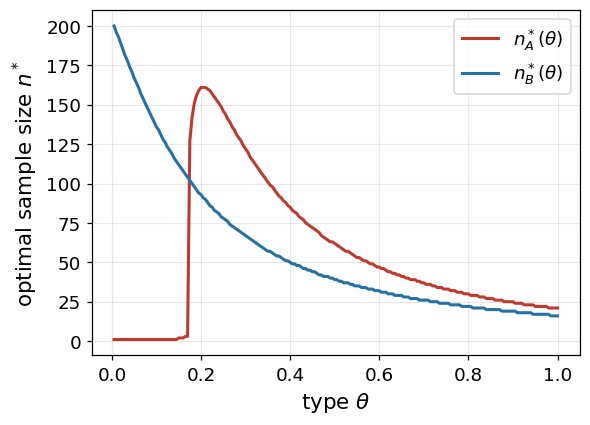

In [19]:
# Panel (a): chosen sample sizes
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(thetas, nA, color=COL_A, label=r"$n_A^*(\theta)$")
ax.plot(thetas, nB, color=COL_B, label=r"$n_B^*(\theta)$")
ax.set_xlabel(r"type $\theta$", fontsize=14)
ax.set_ylabel(r"optimal sample size $n^*$", fontsize=14)
ax.tick_params(axis='both', labelsize=12)
ax.legend(fontsize=12)
plt.tight_layout()
plt.show()


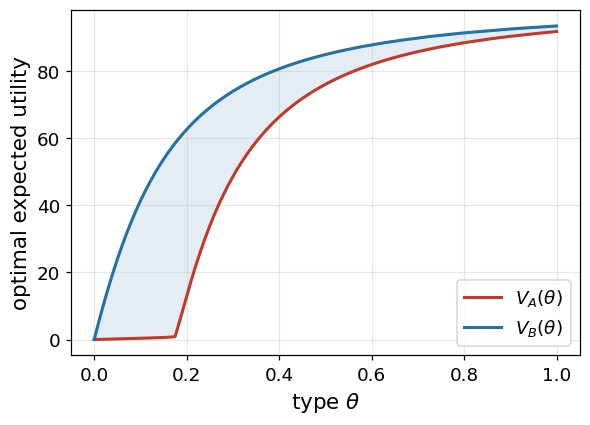

In [20]:
# Panel (b): optimal expected utilities
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(thetas, VA, color=COL_A, label=r"$V_A(\theta)$")
ax.plot(thetas, VB, color=COL_B, label=r"$V_B(\theta)$")
ax.fill_between(thetas, VA, VB, where=VB > VA, color=COL_B, alpha=0.12)
ax.set_xlabel(r"type $\theta$", fontsize=14)
ax.set_ylabel("optimal expected utility", fontsize=14)
ax.tick_params(axis='both', labelsize=12)
ax.legend(loc="lower right", fontsize=12)
plt.tight_layout()
plt.show()


## Headline: passing probability at the agent's optimal sample size

We are plotting $p_A(n_A^*(\theta), \theta)$ vs $p_B(n_B^*(\theta), \theta)$.

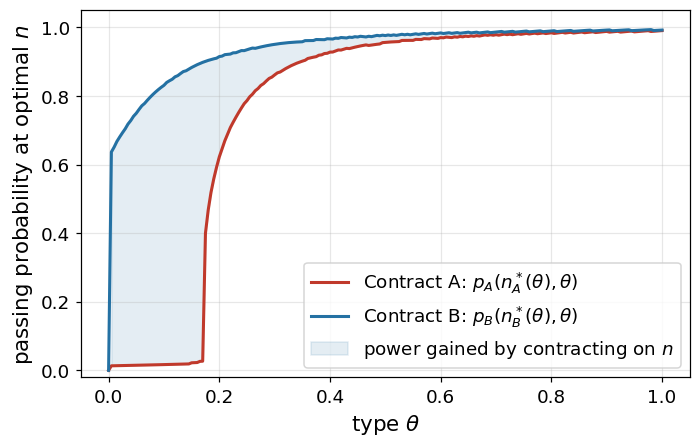

In [21]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(thetas, pA, color=COL_A, label=r"Contract A: $p_A(n_A^*(\theta),\theta)$")
ax.plot(thetas, pB, color=COL_B, label=r"Contract B: $p_B(n_B^*(\theta),\theta)$")
ax.fill_between(thetas, pA, pB, where=pB > pA, color=COL_B, alpha=0.12,
                label="power gained by contracting on $n$")

# 1. Add fontsize=14 to axis labels
ax.set_xlabel(r"type $\theta$", fontsize=14) 
ax.set_ylabel("passing probability at optimal $n$", fontsize=14)

# 2. Increase the size of the tick numbers 
ax.tick_params(axis='both', labelsize=12)

ax.set_ylim(-0.02, 1.05)
ax.legend(loc="lower right", fontsize=12)
plt.tight_layout()
plt.show()

## Shape of the agent's objective

On the evidence scale $s(n) = \theta\sqrt n$, the agent's profit is $v_j(\theta, n) = R\,\Phi\big(s(n) - \tau_j(n)\big) - c(n)$,
with bar $\tau_A \equiv z_A = \Phi^{-1}(1 - c_{\min}/R)$ and $\tau_B(n) = \Phi^{-1}(1 - c(n)/R)$.

- **Contract A** (Proposition 2): $\operatorname{sign} v_A''(n) = -\operatorname{sign} q(s(n))$ with $q(s) = s^2 - z_A s + 1$.
  If $z_A > 2$ the profit is convex exactly on $(n_-, n_+)$, $n_\pm = s_\pm^2/\theta^2$, and concave elsewhere; if $z_A \le 2$ it is concave everywhere.
- **Contract B** (Lemma 2): concave once the expected evidence clears the bar, $u_B(n) \ge 0$.



In [ ]:
n0    = N.min()                                   # cheapest feasible trial
c_min = c0 + c1 * n0
z_A   = norm.ppf(1 - c_min / R)                    # Contract A approval bar
regime = "strict (z_A > 2): convex region exists" if z_A > 2 else "lenient (z_A <= 2): v_A concave"
print(f"z_A = {z_A:.3f}  ->  {regime}")

def tau_B(n):
    return norm.ppf(1 - (c0 + c1 * n) / R)

def v_A(n, theta):   
    return R * passing_prob(n, theta, alpha_A(R, c0, c1, N)) - (c0 + c1 * n)

def v_B(n, theta):
    return R * passing_prob(n, theta, alpha_B(n, R, c0, c1)) - (c0 + c1 * n)

def curv_A(n, theta):
    '''v_A''(n) from Proposition 2.'''
    s = theta * np.sqrt(n)
    return -R * theta * norm.pdf(s - z_A) / (4 * n**1.5) * (s**2 - z_A * s + 1)

def curv_B(n, theta):
    '''v_B''(n) from eq. (vB-second); defined for c(n) < R.'''
    s, tb = theta * np.sqrt(n), tau_B(n)
    u, ph = s - tb, norm.pdf(tb)
    return R * norm.pdf(u) * (-theta / (4 * n**1.5) - theta**2 / (4 * n) * u
                              - theta * c1 / (np.sqrt(n) * R * ph) * u
                              - theta * np.sqrt(n) * c1**2 / (R**2 * ph**2))

if z_A > 2:
    d = np.sqrt(z_A**2 - 4)
    s_minus, s_plus = (z_A - d) / 2, (z_A + d) / 2
    print(f"convex region on the evidence scale: s in ({s_minus:.3f}, {s_plus:.3f})")

n_chk, h = np.linspace(3, 250, 40), 1e-2
for th in (0.12, 0.25, 0.5):
    for v, curv in ((v_A, curv_A), (v_B, curv_B)):
        num = (v(n_chk + h, th) - 2 * v(n_chk, th) + v(n_chk - h, th)) / h**2
        assert np.allclose(num, curv(n_chk, th), rtol=1e-3, atol=1e-6)
print("analytic second derivatives match numerical ones")

z_A = 2.226  ->  strict (z_A > 2): convex region exists
convex region on the evidence scale: s in (0.624, 1.602)
analytic second derivatives match numerical ones


Four types, from weak to strong, under the baseline parameters ($z_A = 2.23 > 2$: strict test).
Rows are contracts, columns are types; the background shows the proven curvature (**amber** = convex, **grey** = concave).
For Contract B only the region above the bar is shaded; below it the curvature is not characterised.

saved fig3_profit_curvature.pdf and fig3_profit_curvature.png


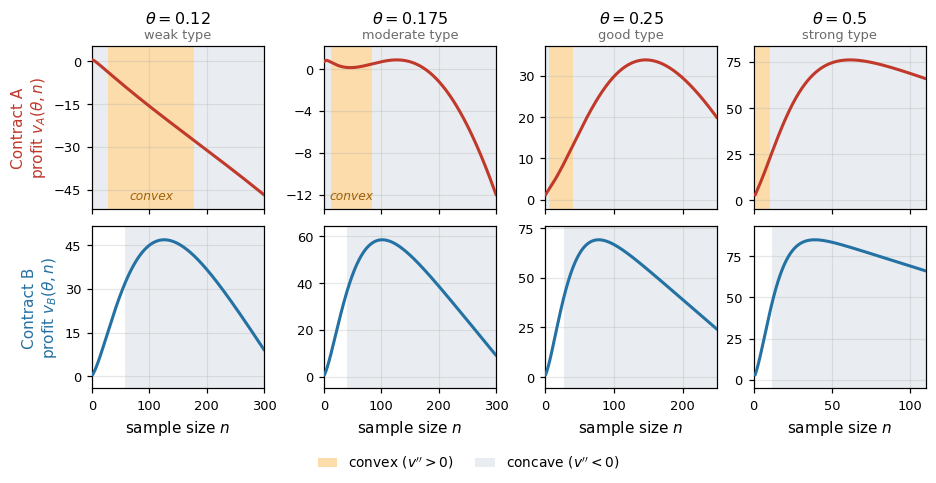

In [ ]:
FIG_STYLE = {
    "axes.titlesize": 10.5,
    "axes.labelsize": 10,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.fontsize": 9,
}
FILL_CONVEX  = "#fbdcaa"    # soft amber: convex   (v'' > 0)
FILL_CONCAVE = "#e9edf1"    # soft grey:  concave  (v'' < 0)
TEXT_CONVEX  = "#a0620a"

def segments(mask, x):
    '''Contiguous x-intervals on which mask is True.'''
    out, start = [], None
    for xi, m in zip(x, mask):
        if m and start is None:
            start = xi
        if not m and start is not None:
            out.append((start, xi)); start = None
    if start is not None:
        out.append((start, x[-1]))
    return out

def shade(ax, intervals, color):
    for a, b in intervals:
        ax.axvspan(a, b, color=color, lw=0, zorder=0)

def draw_panel(ax, theta, xmax, j):
    '''Profit curve of contract j for type theta, on top of its proven curvature regions.
    Contract A: full characterisation (Proposition 2).
    Contract B: concave above the bar (Lemma 2); below the bar left white.'''
    n = np.linspace(n0, xmax, 3000)
    if j == "A":
        convex = curv_A(n, theta) > 0
        shade(ax, [(0, n0)] if not convex[0] else [], FILL_CONCAVE)   # fill left margin
        shade(ax, segments(~convex, n), FILL_CONCAVE)
        conv_iv = segments(convex, n)
        shade(ax, conv_iv, FILL_CONVEX)
        for a, b in conv_iv:                                        # label wide convex stretches
            if (b - a) > 0.16 * (xmax - n0):
                ax.text((a + b) / 2, 0.04, "convex", transform=ax.get_xaxis_transform(),
                        ha="center", va="bottom", fontsize=8, style="italic",
                        color=TEXT_CONVEX)
        v, colr = v_A, COL_A
    else:
        bar_B = brentq(lambda m: theta * np.sqrt(m) - tau_B(m), n0, (R - c0) / c1 - 1e-6)
        shade(ax, [(bar_B, xmax)], FILL_CONCAVE)
        v, colr = v_B, COL_B
    ax.plot(n, v(n, theta), color=colr, lw=2.0, solid_capstyle="round", zorder=3)
    ax.set_xlim(0, xmax)
    ax.margins(y=0.10)
    ax.xaxis.set_major_locator(MaxNLocator(4, steps=[1, 2, 5, 10], integer=True))
    ax.yaxis.set_major_locator(MaxNLocator(4))
    ax.set_axisbelow(True)

def region_legend():
    return [Patch(facecolor=FILL_CONVEX, label=r"convex ($v''>0$)"),
            Patch(facecolor=FILL_CONCAVE, label=r"concave ($v''<0$)")]

def save(fig, fname):
    '''Save as PDF (for the paper) and PNG at 300 dpi (for slides).'''
    fig.savefig(fname + ".pdf", bbox_inches="tight")
    fig.savefig(fname + ".png", dpi=300, bbox_inches="tight")
    print(f"saved {fname}.pdf and {fname}.png")

def plot_profit_curvature(panels, fname):
    '''Rows = contracts, columns = types. Uses the current global parameters (R, c0, c1, n0, z_A).'''
    with plt.rc_context(FIG_STYLE):
        fig, axes = plt.subplots(2, len(panels), figsize=(8.4, 4.3), sharex="col",
                                 layout="constrained")
        for col, (theta, label, xmax) in enumerate(panels):
            for row, (j, colr) in enumerate((("A", COL_A), ("B", COL_B))):
                ax = axes[row, col]
                draw_panel(ax, theta, xmax, j)
                if row == 0:
                    ax.set_title(rf"$\theta = {theta:g}$", pad=15)
                    ax.text(0.5, 1.03, label, transform=ax.transAxes, ha="center",
                            va="bottom", fontsize=8.5, color="#6b6b6b")
                if row == 1:
                    ax.set_xlabel(r"sample size $n$")
                if col == 0:
                    ax.set_ylabel(f"Contract {j}\n" + rf"profit $v_{j}(\theta,n)$", color=colr)
        fig.legend(handles=region_legend(), loc="outside lower center", ncol=3, frameon=False,
                   handlelength=1.4, columnspacing=1.6)
        save(fig, fname)
        plt.show()

panels = [  # (theta, short description, x-range)
    (0.12,  "weak type",     300),
    (0.175, "moderate type", 300),
    (0.25,  "good type",     250),
    (0.50,  "strong type",   110),
]

plot_profit_curvature(panels, "fig3_profit_curvature")


## Lenient test 

Same model and types; only the fixed cost rises from $c_0 = 1$ to $c_0 = 3$. Then $c_{\min}/R = 0.033 \ge 1 - \Phi(2) \approx 0.023$,
so $z_A = 1.84 \le 2$ and, by Proposition 2, Contract A's profit is concave for every type: the convex region disappears.

c_min/R = 0.033,  z_A = 1.838  ->  lenient (z_A <= 2): v_A concave
largest change of n_A* between neighbouring types (dtheta = 0.0005): 4
saved fig3b_profit_curvature_lenient.pdf and fig3b_profit_curvature_lenient.png


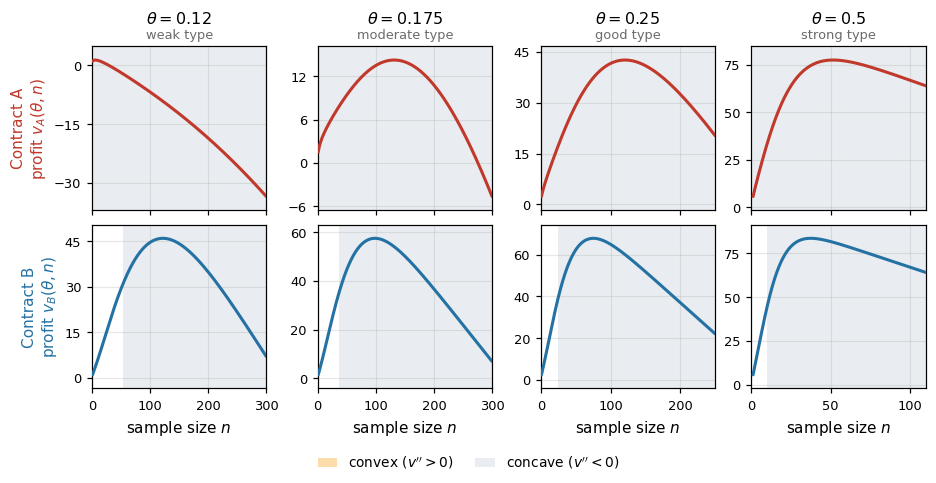

In [ ]:
c0_strict = c0
c0 = 3.0                                   
c_min = c0 + c1 * n0
z_A = norm.ppf(1 - c_min / R)
print(f"c_min/R = {c_min / R:.3f},  z_A = {z_A:.3f}  ->  "
      f"{'lenient (z_A <= 2): v_A concave' if z_A <= 2 else 'strict'}")

# checks: v_A has no convex region, and n_A^*(theta) changes gradually across types
n_chk = np.linspace(n0, 400, 4000)
assert all((curv_A(n_chk, t) <= 1e-12).all() for t in np.linspace(0.02, 1.0, 200))
th_fine = np.linspace(0.02, 1.0, 2000)
nA_fine = np.array([best_response(t, R, c0, c1, N)["A"]["n"] for t in th_fine], float)
print(f"largest change of n_A* between neighbouring types (dtheta = {th_fine[1]-th_fine[0]:.4f}): "
      f"{np.abs(np.diff(nA_fine)).max():.0f}")

panels_lenient = [
    (0.12,  "weak type",     300),
    (0.175, "moderate type", 300),
    (0.25,  "good type",     250),
    (0.50,  "strong type",   110),
]
plot_profit_curvature(panels_lenient, "fig3b_profit_curvature_lenient")

c0 = c0_strict                             # restore the baseline for any later cell
c_min = c0 + c1 * n0
z_A = norm.ppf(1 - c_min / R)